# Integrative Industry Synthesis: ML, GenAI, and Agentic
## In this notebook (Step-4)
- We collect some test results from running our agentic-workflow

# Setup

## Import required modules

In [1]:
from pathlib import Path
import time
import sys
SRC_DIR = str(Path.cwd().parent /'src')
if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)
notebook_start_time = time.time() # Start the global timer
print(f'notebook_start_time={time.ctime(notebook_start_time)}')

notebook_start_time=Sat Oct 10 19:03:03 2026


In [2]:
import importlib
from config import settings, get_test_case_info_df
import utils as ut #use importlib.reload(ut) if reload needed in specific cell during development
import utils_gen as ut_gen
from tools.transaction_db_tools import get_transaction_df
import seaborn as sns
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib # for version check
import matplotlib.pyplot as plt
import torch
from collections import Counter
import joblib
from tqdm.notebook import tqdm
import pprint
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    fbeta_score,
)

from IPython.display import clear_output, display, Image

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
# Enable high-resolution Retina plots
%config InlineBackend.figure_format = 'retina'

In [3]:
print("*" * 75)
print(f'PYTHON VERSION:      {sys.version}')
print(f'PYTHON VPATH:        {sys.executable}')
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("*" * 75)

***************************************************************************
PYTHON VERSION:      3.13.14 (main, Jul 23 2026, 14:44:45) [Clang 22.1.3 ]
PYTHON VPATH:        /home/max/x/zc07-ml-genai-agentic/.venv/bin/python
Pandas version:      2.3.3
NumPy version:       2.5.3
Matplotlib version:  3.11.2
Seaborn version:     0.13.2
***************************************************************************


In [4]:
print(f'Torch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
print(f'CUDA version used: {torch.version.cuda}')

Torch version: 2.14.1+cu130
CUDA available: True
CUDA version used: 13.0


In [5]:
def seed_all(seed:int=42):
    """
    set random seed and cuda related settings for reproducibility
    Args:
        seed: int setting the seed
    Return:
        None
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # Handles CPU and CUDA automatically in modern PyTorch
    # Optional: Only configure CUDA/cuDNN if a GPU is actually present
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    
seed_all(settings.RANDOM_SEED)

# Command Line Options

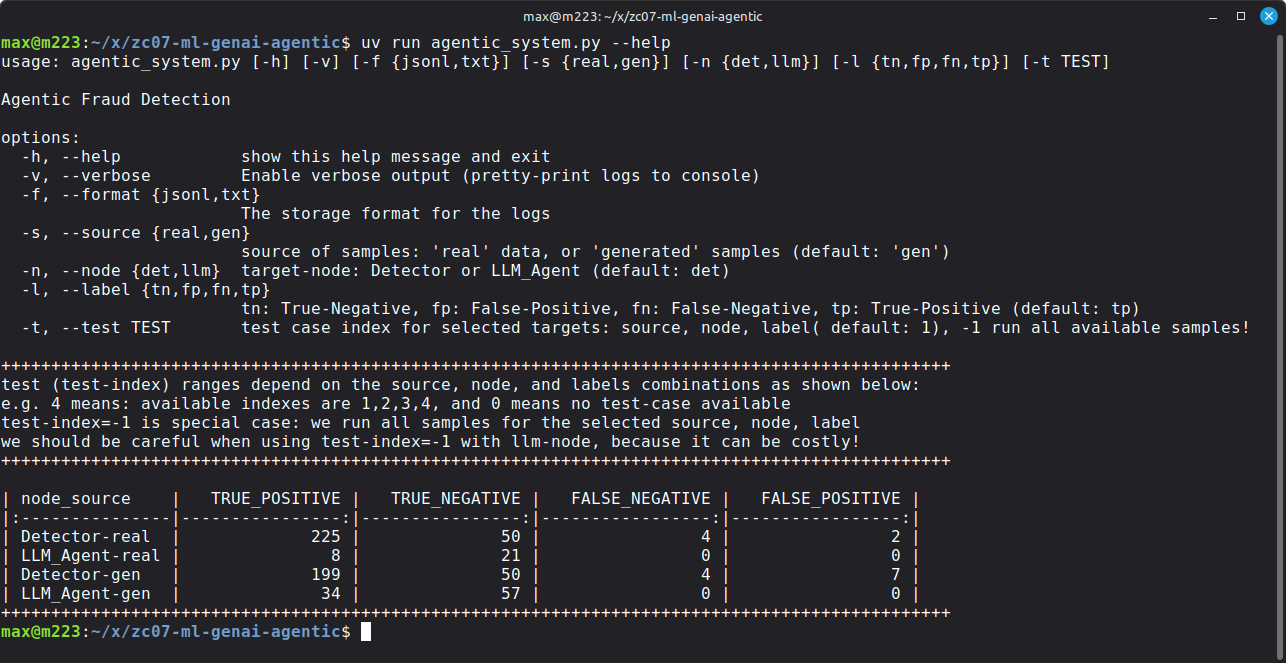

In [6]:
display(Image(filename=settings.IMG_DIR/'z-help.png', width=1200))

# First-Time Run
- First-time run means there is no database, or when we delete the entire out folder
- In this case, the system first check and will create and initiaialze all required database
- For transaction, and checkpoint only table created
- For Long-Term Memory(LTM), we initiate the Chroma Vector-dB, and initialize it with prepared training data at step-3
- Also the workflow-graph saved as shown below

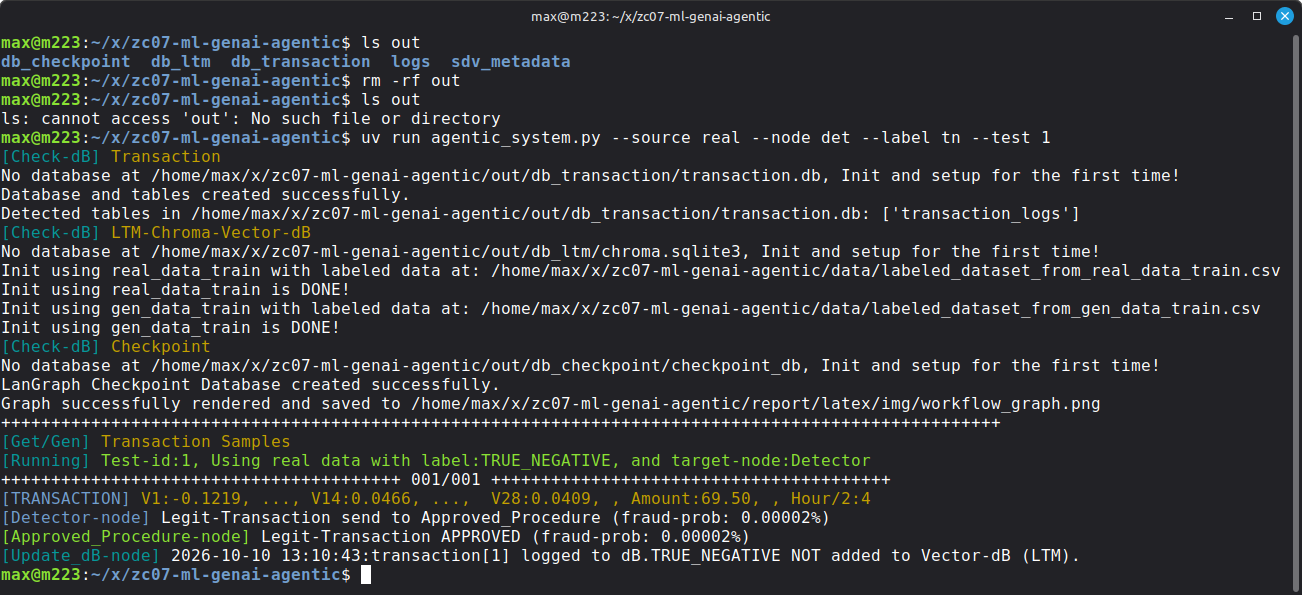

In [7]:
display(Image(filename=settings.IMG_DIR/'z-first-run.png', width=1200))

### NOTE:
- The text-output is very descriptive and shows all steps
- This is TN sample, that can be detected in detector node by the trained ML classifier
- It is flagged as Legit, and send for approval
- The approved procedure node will take care of approval procedure.
- All transaction will be logged into transaction-dB (including both actual and predicted labels for later analysis),
- We do not save True Negative label in LTM (all other label will be save in LTM)

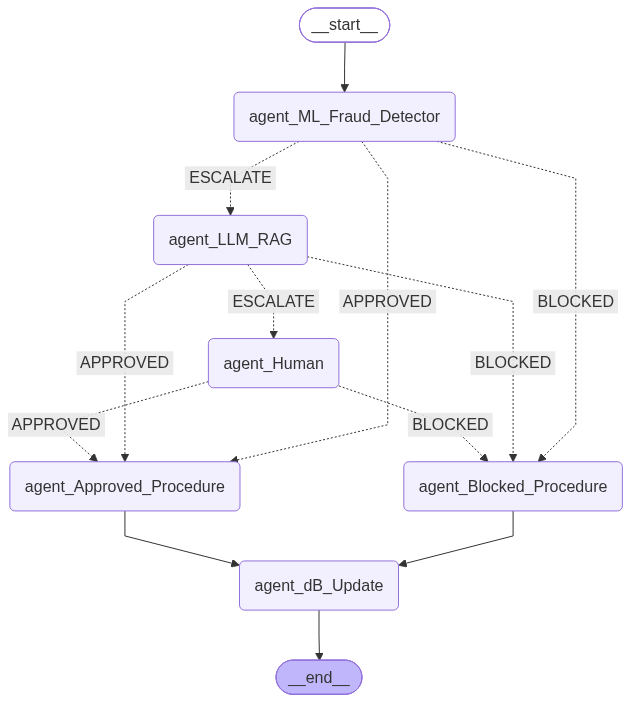

In [8]:
display(Image(filename=settings.IMG_DIR/'workflow_graph.png', width=640))

# Invalid Test-Index
- Valid test-index are 1 to max value shown in the table provided in the help menu
- For example Foe Node=Detector, and Source=gen (generated data),and label = tp (TRUE_POSITIVE) this max is 199
- When Node is LLM_Agent (llm), There is no FP or FN test-case (max-index =0)
- For Detector we have ML-classifier and we already know which samples classified as TP/TN/FP/FN
- But for LLM-Agent we only know that we have TP and TN samples (escalate from ML/Detector node), how LLM classify them is still unknown, and we do not have FN/FP samples for LLM 'yet'.

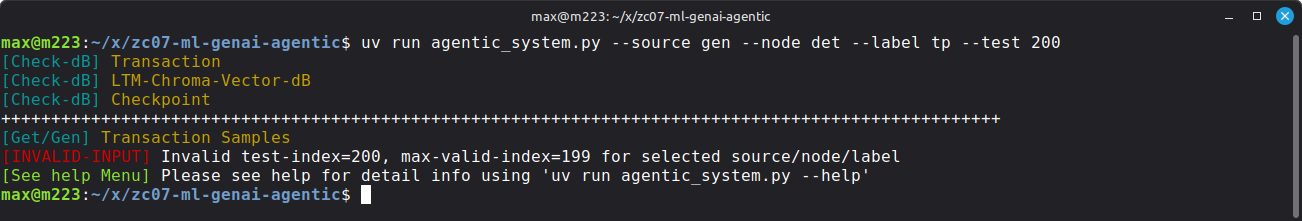

In [9]:
display(Image(filename=settings.IMG_DIR/'z-invalid-index.png', width=1000))

# Sample run for Detector Node with label: TP, FP, and FN
- TN: already shown in first run (above)
- TP: source: gen (generated data), node = det (Detector = ML-Classifier), label: tp (True-Positive), test: 17
- FP: source: real (real data), node = det (Detecto r= ML-Classifier), label: fp (False-Positive), test: 2
- FN: source: gen (generated data), node = det (Detector = ML-Classifier), label: tn (False-Negative), test: 1

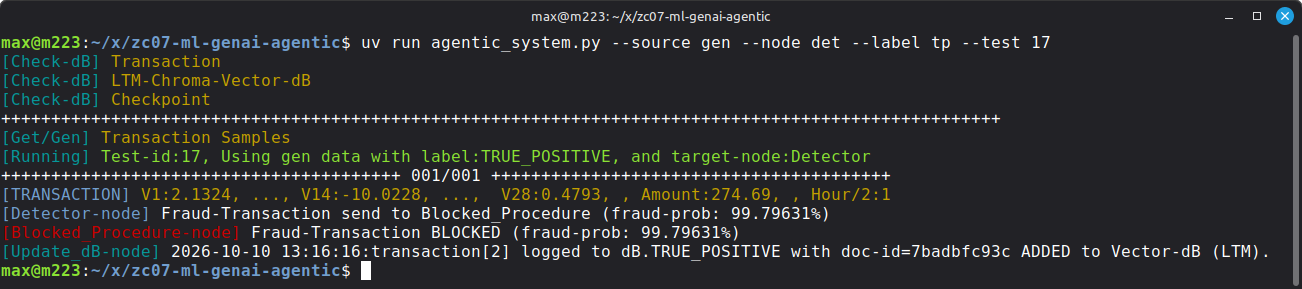

In [10]:
display(Image(filename=settings.IMG_DIR/'z-det-tp.png', width=1200))

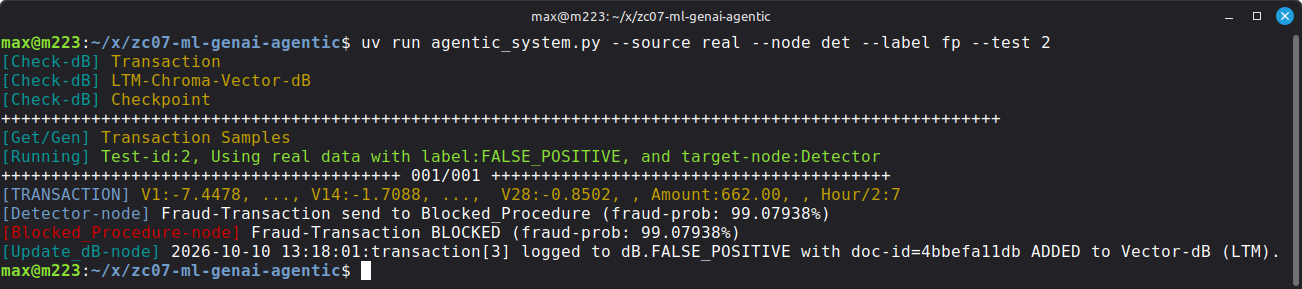

In [11]:
display(Image(filename=settings.IMG_DIR/'z-det-fp.png', width=1200))

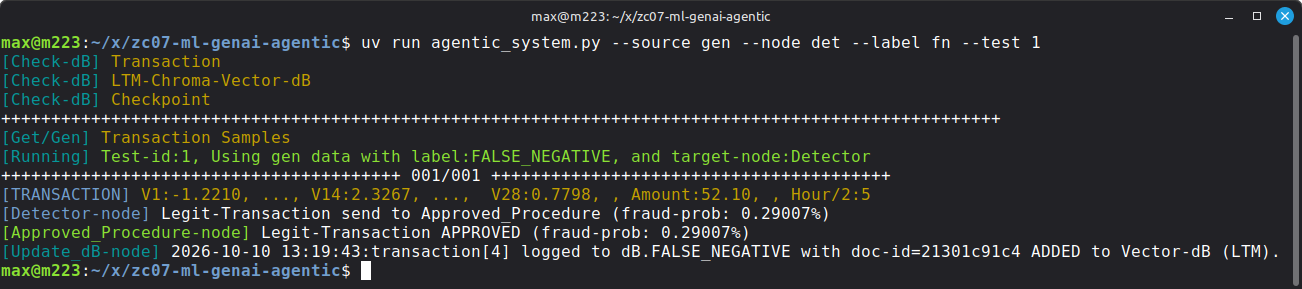

In [12]:
display(Image(filename=settings.IMG_DIR/'z-det-fn.png', width=1200))

# Three Questions and answers
The above FP and FN cases are added to LTM, If we run the same test-case

---
## Questions
1. Is LTM helpful in next run ?
2. Is LTM keep adding redundant data ?
3. Detector wrongly decided on FP/FN, what data got to transaction dB, and how LTM add correct label as FP/FN ?

## Answers
1. No, in Detector Node, we do not use any LTM, and we only use ML-Classifier, It will keep making same decision (mistake) on same data, However using dual thresholds has already reduced the FP/FN, as explained both in confusion-matrix and numerical values in step-3.
2. No When we add data to LTM, we defined a unique-id based on the transaction-data, and same transaction-data provide same unique-id (please see the code), and when we add to Vector-dB we used `upsert` instead of `add` which just update the content of existing ID, in the console output we show if ADDED or UPDATED (as shown in next cell, please check doc-id is the same, first time ADDED, second time Updated)
3. Since we use existing real dataset or we use generative models to generate Legit/Fraud samples, we always know the actual_class, so in transaction database we always add both actual_class and pred_class, for analytical purpose, also when adding to LTM, we use actual_class (which result in corresponding correct label). In reality these actual_label may need to be written, updated after human review, but in our case it is automated in update-database-node.


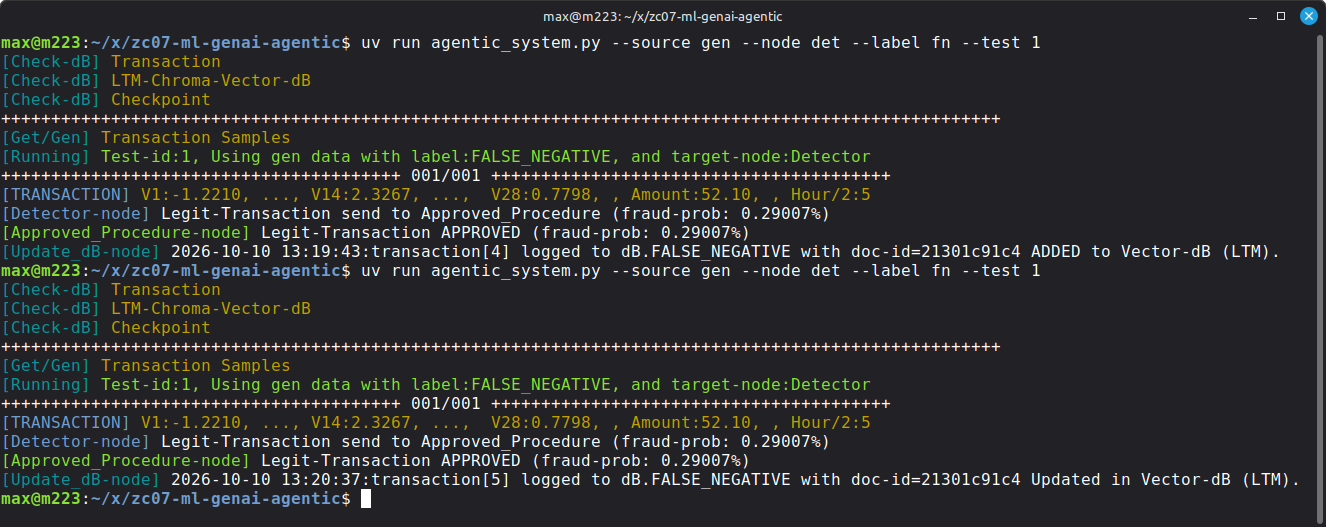

In [13]:
display(Image(filename=settings.IMG_DIR/'z-det-fn-rep.png', width=1200))

# Sample runs for LLM Node with label: TP, TN
- We try some samples
- We also repeat some sample to see the effect of LTM

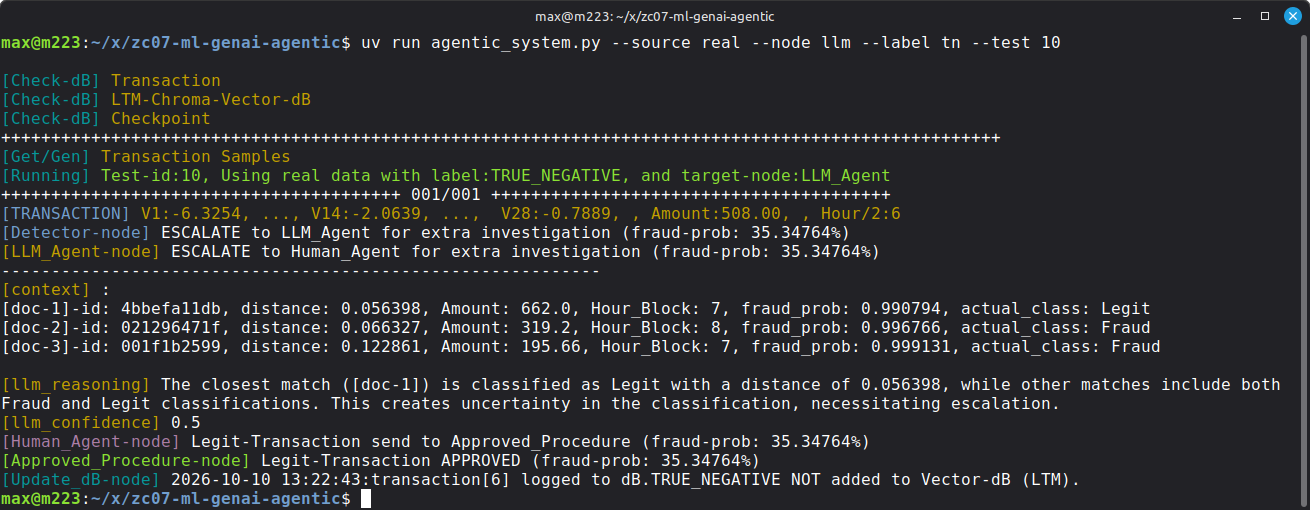

In [14]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tn-10.png', width=1200))

### Note:
- This is indeed very difficult situation
- where the first two context are very similar (both distance, and fraud probability)
- with one legit and the other as fraud
- Not simple even for human, expected to escalate

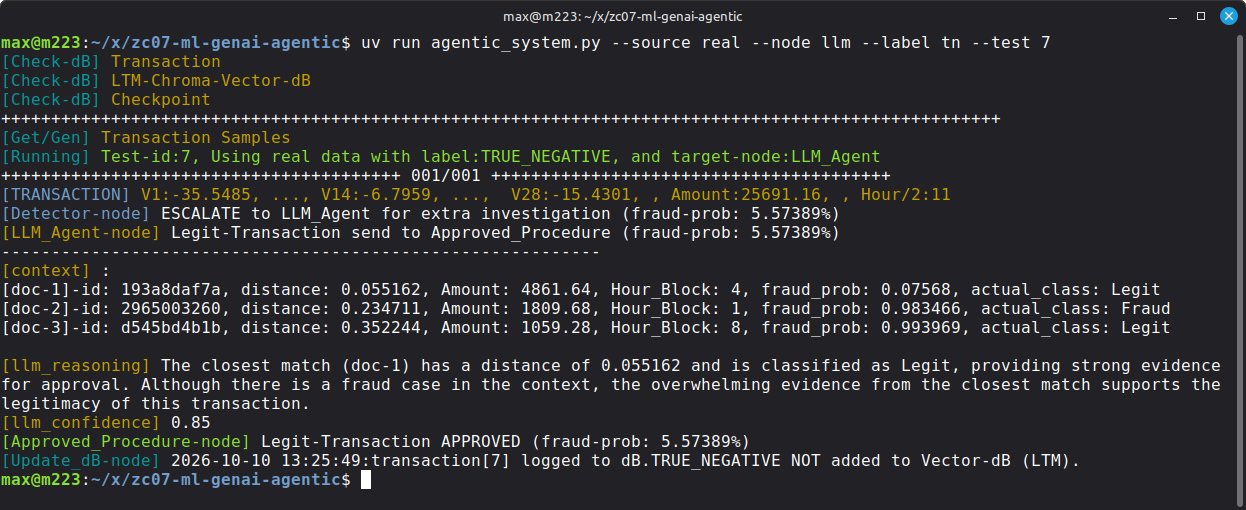

In [15]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tn-07.png', width=1200))

### Note
- Good reasoning by LLM

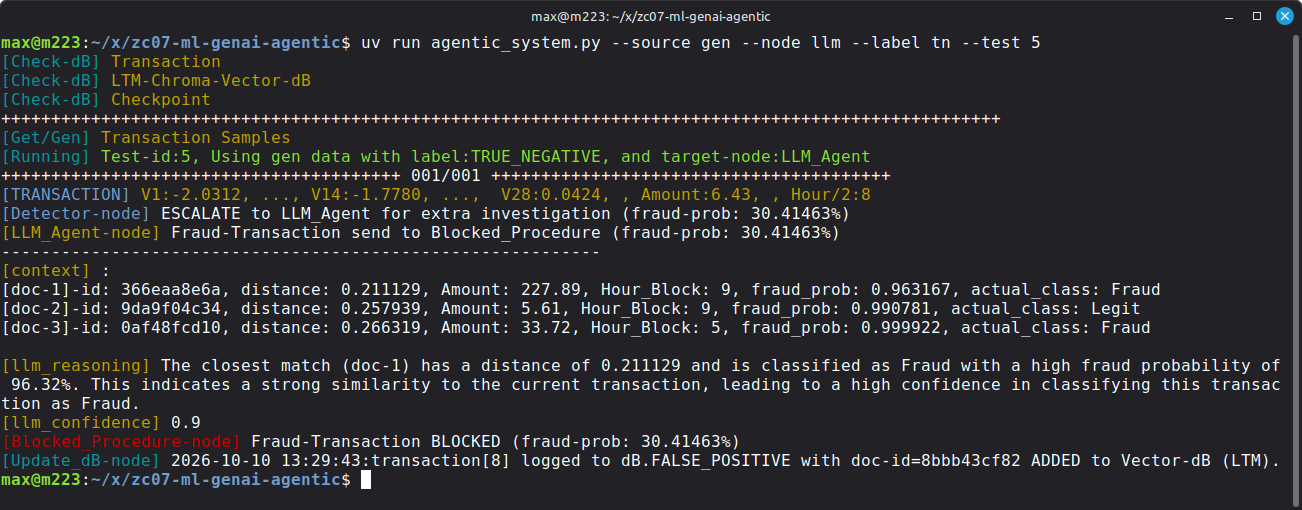

In [16]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tn-05.png', width=1200))

### Note: FALSE-POSITIVE Created by LLM-Agent
- Having close distance, and high fraud-probability of fraud on 2 out of 3, cause agent mistake and create FALSE-POSITIVE

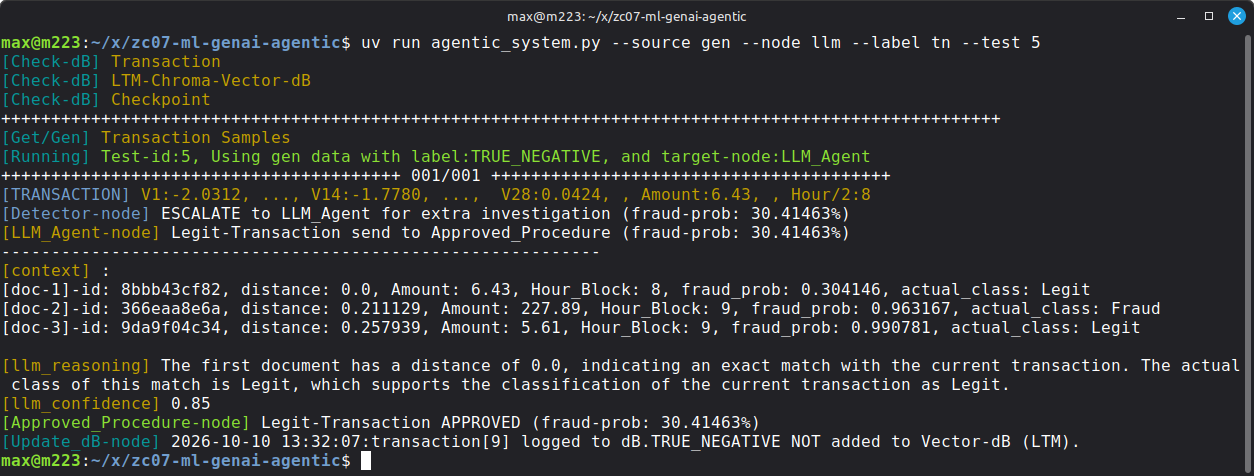

In [17]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tn-05-rep1.png', width=1200))

### Note: Effect of LTM on guiding LLM on its previous mistake
- Having distance zero (or close to zero), help LLM-Agent to have better decision

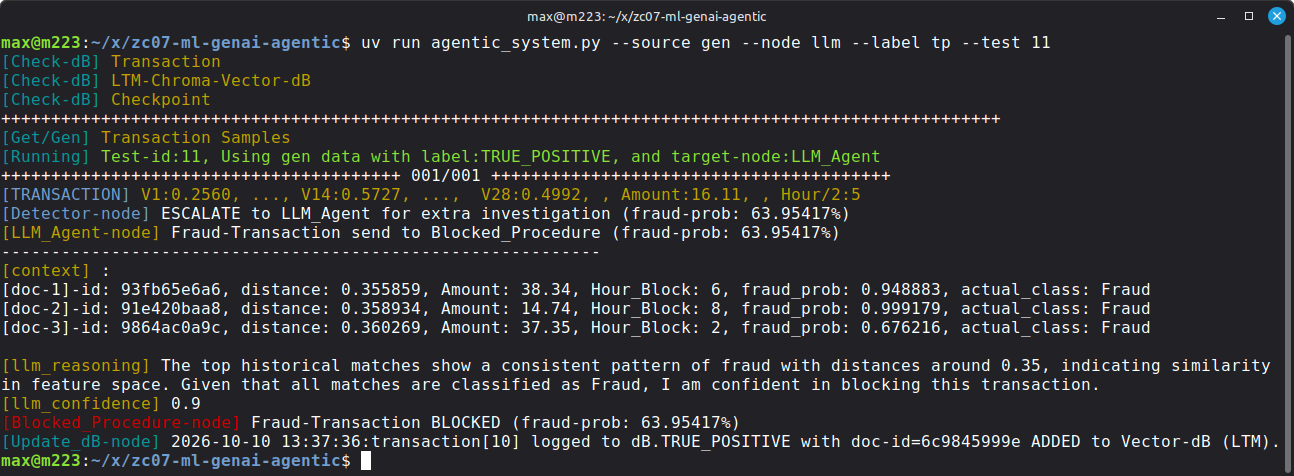

In [18]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tp-11.png', width=1200))

### Note
- Not ambiguous, and since TP, it is also added to LTM

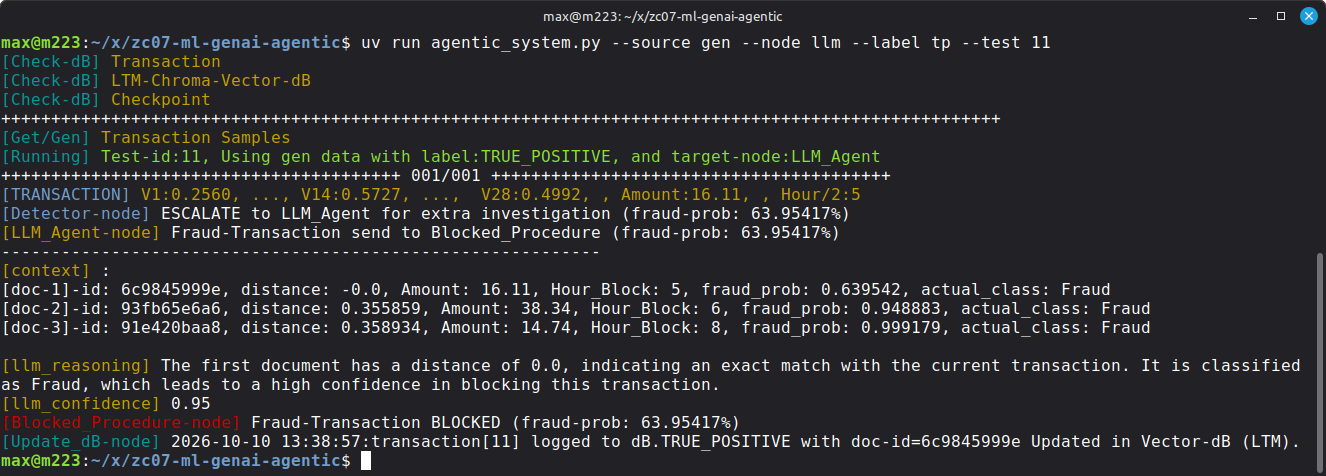

In [19]:
display(Image(filename=settings.IMG_DIR/'z-llm-gen-tp-11-rep1.png', width=1200))

### Note
- Initially was not ambiguous, and now agent is more confident (LTM just updated the same doc-id)

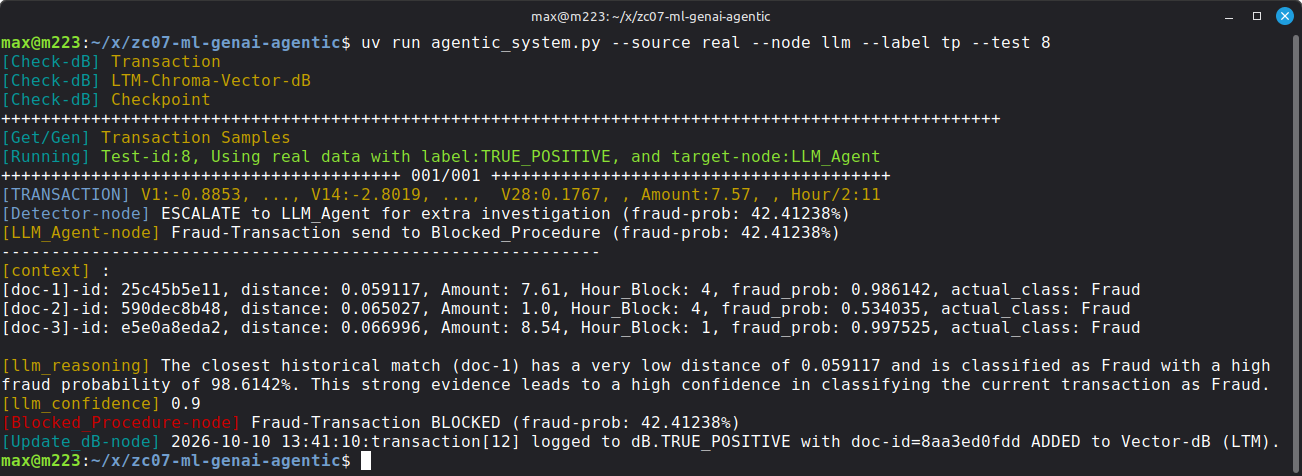

In [20]:
display(Image(filename=settings.IMG_DIR/'z-llm-real-tp-08.png', width=1200))

### Note
- Testin TP on LLM_Agent with sample from real data (not a difficult case for LLM-Agent !)

# Test Case Count Info

In [35]:
dfix = get_test_case_info_df()
dfix=dfix.set_index('node_source')
dfix['Test_Case_Count']=dfix.sum(axis=1)
dfix

,TRUE_POSITIVE,TRUE_NEGATIVE,FALSE_NEGATIVE,FALSE_POSITIVE,Test_Case_Count
node_source,,,,,
Detector-real,225,50,4,2,281
LLM_Agent-real,8,21,0,0,29
Detector-gen,199,50,4,7,260
LLM_Agent-gen,34,57,0,0,91


In [36]:
total_test_case = dfix.Test_Case_Count.sum()
print(f'Total Test-Case Count: {total_test_case}')

Total Test-Case Count: 661


# Run All Test Cases
- In total we have 225+8+199+34+50+21+50+57+4+4+2+7 = 661 test cases

In [75]:
# We can check the log for first run
!cat ../data/run_all_test_log_cleaned.txt | grep "run_all_test\|finished"

max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh det
Script finished in 8m 17s (Total: 497 seconds).
max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh llm
Script finished in 15m 11s (Total: 911 seconds).


In [76]:
# Also we can check the log for second run
!cat ../data/run_all_test_log2_cleaned.txt | grep "run_all_test\|finished"

max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh det
Script finished in 9m 44s (Total: 584 seconds).
max@m223:~/x/zc07-ml-genai-agentic$ ./run_all_test.sh llm
Script finished in 15m 6s (Total: 906 seconds).


In [66]:
# We can get and save db like below, but in this notebook we use the saved data
#df = get_transaction_df()
#df.to_csv(settings.DATA_DIR/'all_test_case_runx2_trans_db.csv', index = False)
df = pd.read_csv(settings.DATA_DIR/'all_test_case_runx2_trans_db.csv')
print(df.shape)
df.iloc[:,np.r_[0:4,-7:0]].head()

(1322, 35)


,index,timestamp,V1,V2,V27,V28,Amount,HourT,actual_class,pred_class,source_id
0,1,2026-10-10 13:49:22.947978,-0.121876,-0.371387,0.033161,0.040867,69.50,4,0,0,real
1,2,2026-10-10 13:49:23.374261,1.968480,-0.461075,0.045268,-0.045286,1.00,10,0,0,real
2,3,2026-10-10 13:49:23.841096,2.043776,-0.094650,-0.073732,-0.073163,0.89,8,0,0,real
3,4,2026-10-10 13:49:24.326238,-4.066862,-5.081215,-0.057777,-0.532404,355.51,0,0,0,real
4,5,2026-10-10 13:49:24.824281,1.505781,-1.366895,0.027691,0.017529,49.95,11,0,0,real


In [47]:
L=len(df)
L2 = L //2
df1=df.iloc[:L2,:].copy()
print(df1.shape)
df2=df.iloc[L2:,:].copy()
print(df2.shape)

(661, 35)
(661, 35)


In [62]:
sns_cmaps=['Blues_r','Greens_r', 'Reds_r']
def plot_confusion_matrix_from_test_results_transaction_df(df, sns_cmap, ext_ax, title, run_index)->dict[str, float]:
    """
    A helper function to plot Confusion Matrix from actual_class, and pred_class in transaction dB
    and return calculated metrics: accuracy, precision, recall, f1-score, f2-score
    Args:
        - df: dataframe of transction
        - sns_cmap: map used for plotting
        - ext_ax: axis for plot
        - title for plot        
    Returns:
        metric dict
    """
    try:
        y = df.actual_class
        y_pred = df.pred_class
        cm = confusion_matrix(y, y_pred)
        cm_xytick=['Not-Fraud', 'Fraud']

        sns.heatmap(cm, annot=True, fmt='d', cmap=sns_cmap, xticklabels=cm_xytick, yticklabels=cm_xytick, ax=ext_ax, annot_kws={'size': 14})
        accuracy = accuracy_score(y, y_pred)
        precision = precision_score(y, y_pred, average="binary", zero_division=0)
        recall = recall_score(y, y_pred, average="binary", zero_division=0)
        f1 = f1_score(y, y_pred, average="binary", zero_division=0)
        f2 = fbeta_score(y, y_pred, average='binary', zero_division=0, beta = 2)       
        ext_ax.set_title(title, fontsize=11)
        ext_ax.set_xlabel('Predicted Label', fontsize=12)
        ext_ax.set_ylabel('True Label', fontsize=12)
        #---------------------------------------------------
       
        metric={
            "Run": f'Run_{run_index}',
            "Accuracy":  accuracy,
            "Precision": precision,
            "Recall":    recall,
            "F1-Score":  f1,
            "F2-Score":  f2,
        }
        return metric

    except Exception as e:
        #logger.error(f'Error in plot_confusion_matrix: {e}')
        raise


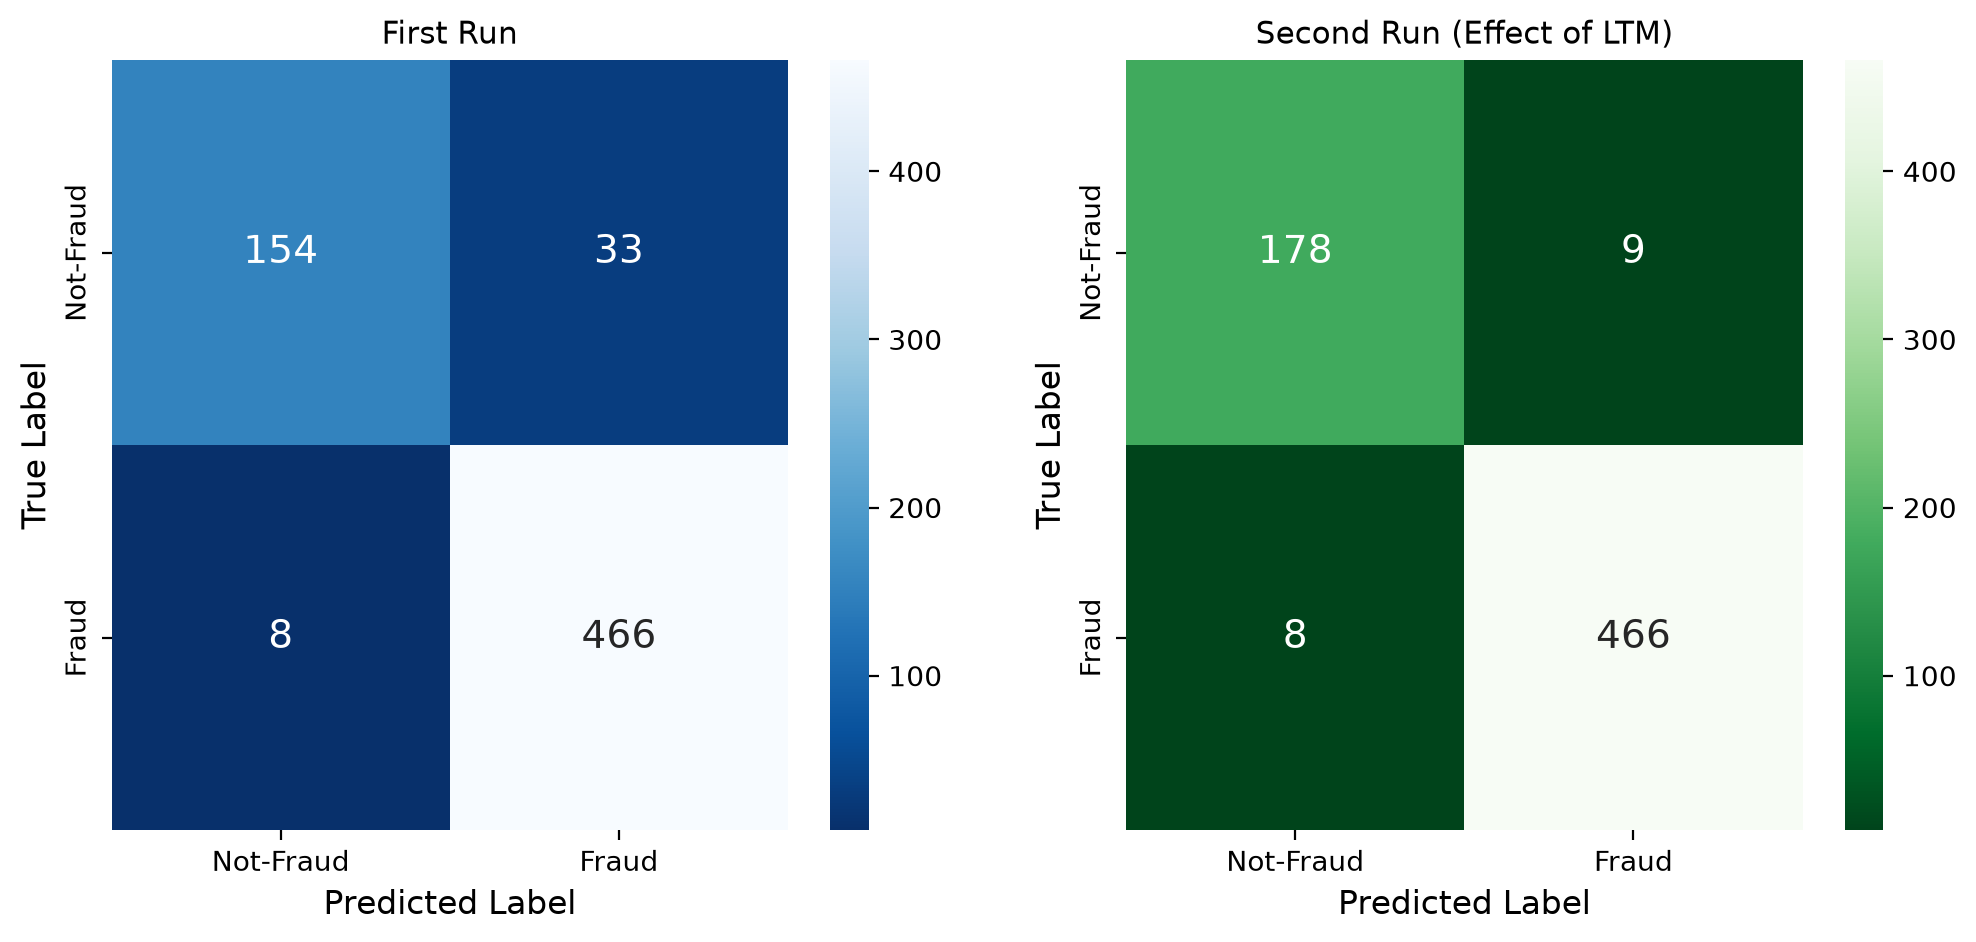

In [63]:
fig, axs=plt.subplots(1,2,figsize=(12, 5))
titles=['First Run', 'Second Run (Effect of LTM)']
dfs=[df1, df2]
metrics=[]
for j, (titlej,dfj) in enumerate(zip(titles, dfs)):
    metric=plot_confusion_matrix_from_test_results_transaction_df(dfj,sns_cmaps[j], axs[j], titlej, j+1)
    metrics.append(metric)
metrics_df=pd.DataFrame(metrics)
#metrics_df

In [61]:
metrics_df= metrics_df.set_index('Run')
metrics_df = (100*metrics_df).round(2)
metrics_df

,Accuracy,Precision,Recall,F1-Score,F2-Score
Run,,,,,
Run_1,93.80,93.39,98.31,95.79,97.29
Run_2,97.43,98.11,98.31,98.21,98.27


### Elapsed Time

In [31]:
# Calculate elapsed time
total_elapsed_time = time.time() - notebook_start_time
minutes = int(total_elapsed_time // 60)
seconds = total_elapsed_time % 60
print(f"Total Notebook Execution Time: {minutes} minutes and {seconds:.2f} seconds")

Total Notebook Execution Time: 0 minutes and 7.16 seconds


# Summary

1. 